# Parte 1: datos y modelo de predicción de PM2.5

Este notebook documenta los datos, el análisis exploratorio, los modelos implementados desde cero (regresión Ridge y Naive Bayes categórico) y su evaluación frente a líneas base con validación temporal. El código reutilizable está en `src/`.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from datos import cargar_diario, cargar_clima, cargar_estaciones, construir_dataset, CLASES
import modelo as M
pd.set_option("display.width", 160)

## 1. Datos

PM2.5 horario de 21 estaciones del SIATA entre el 31 de julio de 2023 y el 31 de julio de 2024, obtenido del archivo público `https://siata.gov.co/EntregaData1/Datos_SIATA_Aire_pm25.json`. Se descartan los datos con indicador de calidad mayor o igual a 2.6, los valores negativos y los mayores a 500. El promedio diario se calcula solo si hay al menos 18 horas válidas.

Clima diario de Medellín (lluvia, viento, temperatura, humedad y radiación) de la API de archivo de Open-Meteo, basada en el reanálisis ERA5.

In [2]:
diario = cargar_diario()
est = cargar_estaciones()
clima = cargar_clima()
cobertura = diario.groupby("nombre_corto").agg(dias=("fecha", "count"), pm25_medio=("pm25_media", "mean")).sort_values("dias")
print("Estaciones con datos:", diario.serial.nunique(), "de", len(est))
print("Días estación válidos:", len(diario))
cobertura.round(1)

Estaciones con datos: 17 de 21
Días estación válidos: 5870


,dias,pm25_medio
nombre_corto,,
MED-LAYE,234,16.1
MED-ALTA,342,21.9
CEN-TRAF,345,26.8
CAL-JOAR,346,19.2
MED-TESO,346,18.6
MED-ARAN,347,19.3
MED-SCRI,347,17.4
BEL-FEVE,349,16.6
BAR-TORR,350,14.5


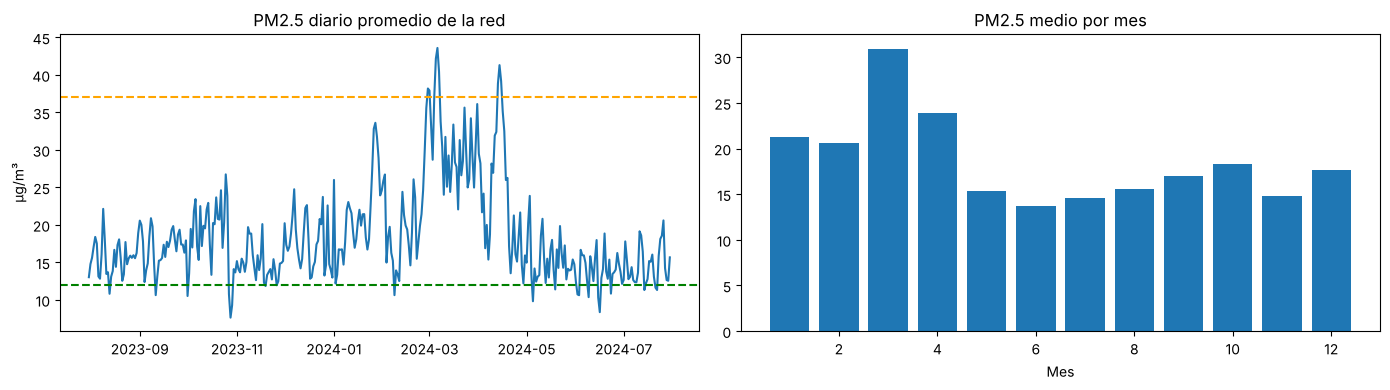

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
red = diario.groupby("fecha")["pm25_media"].mean()
ax[0].plot(red.index, red.values)
for y, c in [(12, "green"), (37, "orange")]:
    ax[0].axhline(y, ls="--", c=c)
ax[0].set_title("PM2.5 diario promedio de la red"); ax[0].set_ylabel("µg/m³")
mes = diario.groupby(diario.fecha.dt.month)["pm25_media"].mean()
ax[1].bar(mes.index, mes.values); ax[1].set_title("PM2.5 medio por mes"); ax[1].set_xlabel("Mes")
plt.tight_layout(); plt.show()

In [4]:
ds = construir_dataset()
print(ds["clase_manana"].value_counts())
cor = ds[["pm25_manana", "pm25_media", "pm25_ayer", "lluvia_mm", "viento_media_kmh", "radiacion_mj", "humedad_media"]].corr()["pm25_manana"].round(3)
cor

clase_manana
Aceptable    4494
Buena         937
Dañina        183
Name: count, dtype: int64


pm25_manana         1.000
pm25_media          0.816
pm25_ayer           0.703
lluvia_mm          -0.169
viento_media_kmh    0.193
radiacion_mj        0.194
humedad_media      -0.294
Name: pm25_manana, dtype: float64

El PM2.5 de mañana depende sobre todo del de hoy, con correlación de 0.82. La lluvia (-0.17) y la humedad (-0.29) tienen correlación negativa, coherente con la limpieza de la atmósfera en días lluviosos. El viento y la radiación tienen correlación positiva débil, porque en este valle los días secos y soleados coinciden con más viento, de modo que esas variables reflejan sobre todo la temporada y no un efecto directo. Las clases están desbalanceadas, con 183 de 5614 casos en categoría Dañina, por lo que se reportan F1 macro y recall de esa clase además de la exactitud.

## 2. Modelos implementados

Regresión Ridge (`M.RegresionRidge`): se resuelve por ecuaciones normales $(A^TA + \lambda I)w = A^T\log(1+y)$ sin penalizar el intercepto. Luego el valor se convierte en clase con cortes que se ajustan por validación cruzada en bloques dentro del entrenamiento para maximizar el F1 macro.

Naive Bayes categórico (`M.NaiveBayesCategorico`): variables discretizadas (clase de hoy, tendencia, lluvia, viento, temporada y día) con suavizado de Laplace.

Se verifica que la implementación de Ridge coincide con la de scikit learn.

In [5]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
d2 = M.preparar(ds)
X = M.variables_regresion(d2, sorted(d2.serial.unique()))
propio = M.RegresionRidge(1.0).ajustar(X, d2.pm25_manana).predecir(X)
Z = StandardScaler().fit_transform(X)
ref = np.expm1(Ridge(alpha=1.0).fit(Z, np.log1p(d2.pm25_manana)).predict(Z))
print("Diferencia máxima con scikit learn:", float(np.abs(propio - ref).max()))
assert np.allclose(propio, ref, atol=1e-6)

Diferencia máxima con scikit learn: 1.2150280781497713e-12


## 3. Validación temporal

Para cada mes de noviembre de 2023 a julio de 2024 se entrena con todos los días anteriores y se prueba en ese mes. Así nunca se usa información del futuro. Líneas base: persistencia (mañana igual a hoy) y clase mayoritaria.

In [6]:
p = M.validacion_temporal(ds, M.MESES_PRUEBA)
tabla = M.tabla_metricas(p)
tabla.round(3)

,MAE,accuracy,f1_macro,recall_Dañina,precision_Dañina,recall_Buena
Ridge + umbrales ajustados,3.414,0.804,0.676,0.692,0.481,0.629
Ridge con cortes ICA,3.414,0.832,0.646,0.522,0.664,0.329
Naive Bayes,NaN,0.801,0.550,0.297,0.562,0.285
Persistencia,3.609,0.818,0.685,0.604,0.604,0.569
Clase mayoritaria,NaN,0.786,0.293,0.000,0.000,0.000


In [7]:
por_mes = p.groupby("mes").apply(lambda g: pd.Series({
    "MAE_ridge": np.mean(np.abs(g.valor_ridge - g.pm25_manana)),
    "MAE_persistencia": np.mean(np.abs(g.pm25_media - g.pm25_manana)),
    "dias_daninos": int((g.clase_manana == "Dañina").sum())}), include_groups=False)
por_mes.round(2)

,MAE_ridge,MAE_persistencia,dias_daninos
mes,,,
2023-11-01,2.63,2.67,0.0
2023-12-01,3.35,3.43,1.0
2024-01-01,3.78,3.55,10.0
2024-02-01,3.77,3.73,19.0
2024-03-01,5.43,5.04,96.0
2024-04-01,3.79,4.46,55.0
2024-05-01,2.89,3.65,1.0
2024-06-01,2.37,3.00,0.0
2024-07-01,2.42,2.74,0.0


In [8]:
def confusion(y, yp):
    return pd.crosstab(pd.Series(y, name="real"), pd.Series(yp, name="predicho")).reindex(index=CLASES, columns=CLASES, fill_value=0)
print("Ridge con umbrales ajustados"); print(confusion(p.clase_manana.values, p.pred_ridge.values))
print("\nPersistencia"); print(confusion(p.clase_manana.values, p.pred_persistencia.values))

Ridge con umbrales ajustados
predicho   Buena  Aceptable  Dañina
real                               
Buena        451        266       0
Aceptable    364       2799     136
Dañina         0         56     126

Persistencia
predicho   Buena  Aceptable  Dañina
real                               
Buena        408        309       0
Aceptable    312       2915      72
Dañina         0         72     110


## 4. Análisis

La regresión Ridge reduce el error absoluto medio de 3.61 a 3.41 µg/m³ frente a la persistencia, una mejora cercana al 5 %. La tabla por mes muestra que la ganancia se concentra en los meses tranquilos, de abril a julio, mientras que en enero y marzo la persistencia tiene menor error. En la temporada crítica el PM2.5 cambia de forma brusca por condiciones meteorológicas que el modelo no conoce de antemano, como la llegada de las lluvias. Con los cortes ajustados detecta el 69 % de los días que terminan en categoría Dañina, frente al 60 % de la persistencia, a costa de más falsas alarmas (precisión de 0.48 frente a 0.60).

En F1 macro la persistencia sigue siendo ligeramente superior (0.685 frente a 0.676). Es una línea base fuerte porque el PM2.5 cambia lento y las categorías tienen cortes fijos. El Naive Bayes queda por debajo de ambas porque la discretización pierde información y sus variables no son independientes, lo que muestra que la suposición de independencia condicional es demasiado fuerte para este problema.

Para alertas de salud se prefiere el modelo Ridge con umbrales ajustados, porque perder un día dañino es más costoso que una falsa alarma. Ese es el modelo que usa la herramienta `predict_tomorrow` del agente.

Limitaciones: un solo año de datos, clima de un único punto de Medellín para todo el valle, sin pronóstico meteorológico del día siguiente y pocos días en categoría Dañina, lo que hace inestables las métricas de esa clase.

In [9]:
M.entrenar_final(ds)
print(open("../data/processed/modelo_ridge.json").read()[:300])

{
 "lam": 1.0,
 "seriales": [
  12,
  28,
  38,
  44,
  69,
  78,
  79,
  80,
  81,
  82,
  83,
  84,
  85,
  86,
  87,
  88,
  90
 ],
 "columnas": [
  "pm25_hoy",
  "pm25_ayer",
  "ciudad_hoy",
  "lluvia_mm",
  "viento_kmh",
  "radiacion_mj",
  "temporada_critica",
  "manana_fin_semana",
  "hoy_fin
